<a href="https://colab.research.google.com/github/HanHoHyeong/H3/blob/main/%EB%B9%85%EB%8D%B0%EC%9D%B4%ED%84%B0%EB%B6%84%EC%84%9D_%EA%B3%BC%EC%A0%9C3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install shap xgboost lightgbm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('titanic')
df = df[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]

print(f"데이터 크기: {df.shape}")

df.head()

데이터 크기: (891, 8)


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


/tmp/ipykernel_916/2605177744.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='survived', data=df, ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_916/2605177744.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='survived', y='fare', data=df, ax=axes[1, 0], palette='Set2')


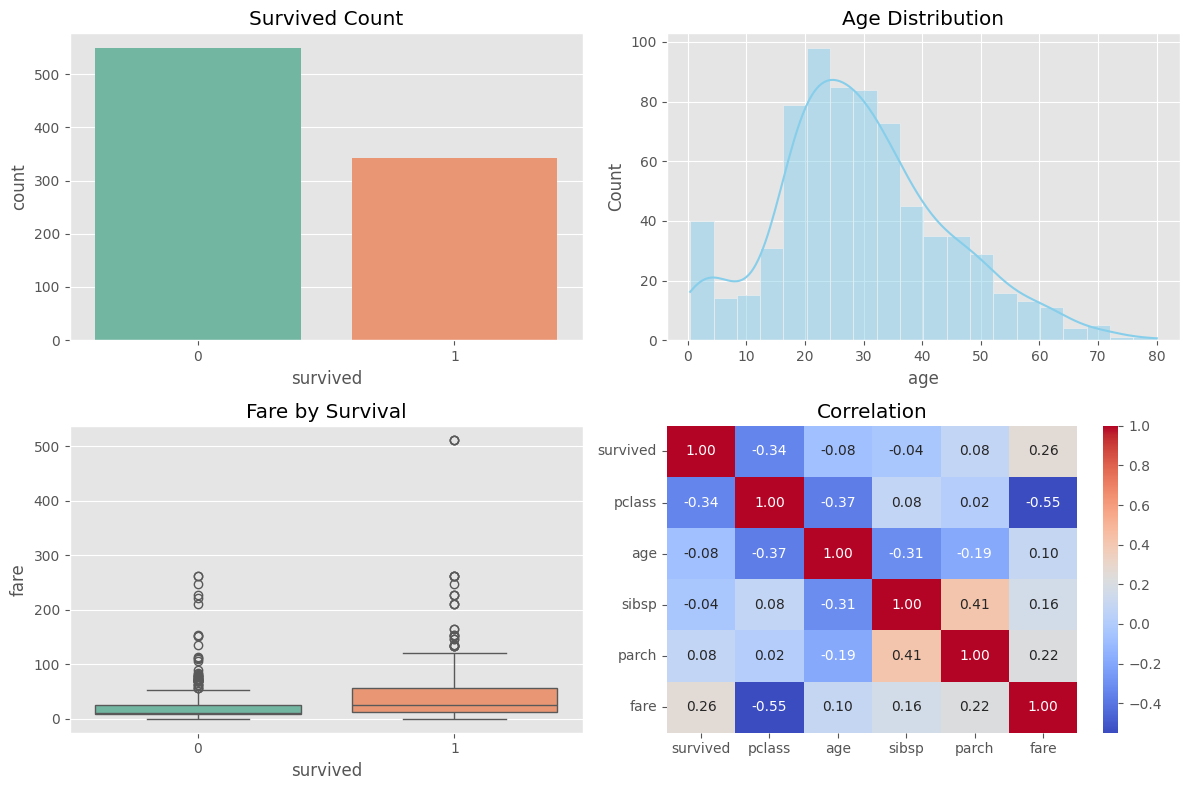

결측치 개수:
 survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


In [7]:
plt.style.use('ggplot')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(x='survived', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Survived Count')

sns.histplot(df['age'].dropna(), kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Age Distribution')

sns.boxplot(x='survived', y='fare', data=df, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Fare by Survival')

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title('Correlation')

plt.tight_layout()
plt.show()

print("결측치 개수:\n", df.isnull().sum())

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df['family_size'] = df['sibsp'] + df['parch'] + 1
df['fare_per_person'] = df['fare'] / df['family_size']

X = df.drop('survived', axis=1)
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ['age', 'sibsp', 'parch', 'fare', 'family_size', 'fare_per_person']
cat_cols = ['pclass', 'sex', 'embarked']

num_base = Pipeline([('imputer', SimpleImputer(strategy='mean'))])
cat_base = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
prep_base = ColumnTransformer([('num', num_base, num_cols), ('cat', cat_base, cat_cols)])

num_exp = Pipeline([('imputer', SimpleImputer(strategy='median')),
                    ('scaler', StandardScaler())])
cat_exp = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore'))])
prep_exp = ColumnTransformer([('num', num_exp, num_cols), ('cat', cat_exp, cat_cols)])

print("파이프라인 세팅 완료")

파이프라인 세팅 완료


In [9]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def get_scores(model, X_test, y_test, exp_name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Experiment': exp_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

results = []

pipe_base = Pipeline([('prep', prep_base), ('clf', RandomForestClassifier(random_state=42))])
pipe_base.fit(X_train, y_train)
results.append(get_scores(pipe_base, X_test, y_test, 'Base (Mean, RF)'))

pipe_exp1 = Pipeline([('prep', prep_exp), ('clf', RandomForestClassifier(random_state=42))])
params = {'clf__n_estimators': [50, 100], 'clf__max_depth': [5, 10]}

grid_rf = GridSearchCV(pipe_exp1, params, cv=3, scoring='accuracy')
grid_rf.fit(X_train, y_train)
results.append(get_scores(grid_rf.best_estimator_, X_test, y_test, 'Exp-1 (Median, Scaled, RF)'))

pipe_exp2 = Pipeline([('prep', prep_exp), ('clf', LGBMClassifier(random_state=42, verbose=-1))])
pipe_exp2.fit(X_train, y_train)
results.append(get_scores(pipe_exp2, X_test, y_test, 'Exp-2 (Median, Scaled, LightGBM)'))

res_df = pd.DataFrame(results).round(4)
res_df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC
0,"Base (Mean, RF)",0.8101,0.7612,0.7391,0.7500,0.8204
1,"Exp-1 (Median, Scaled, RF)",0.7989,0.7895,0.6522,0.7143,0.8252
2,"Exp-2 (Median, Scaled, LightGBM)",0.7989,0.7538,0.7101,0.7313,0.8204


/tmp/ipykernel_916/324542108.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=imp_df, palette='viridis')


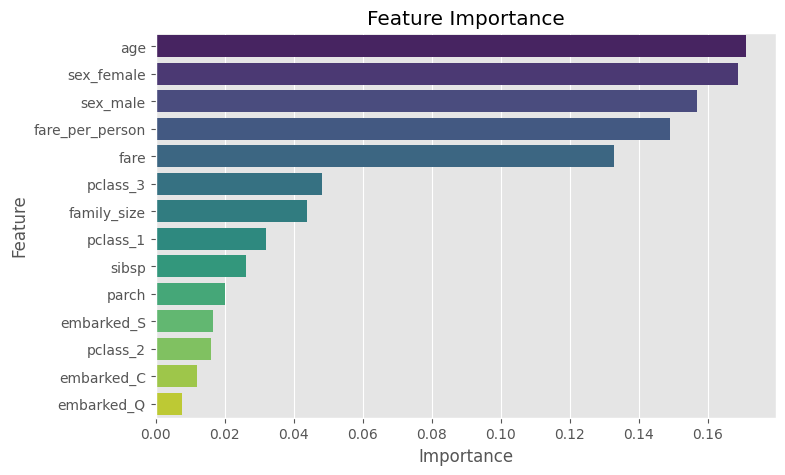

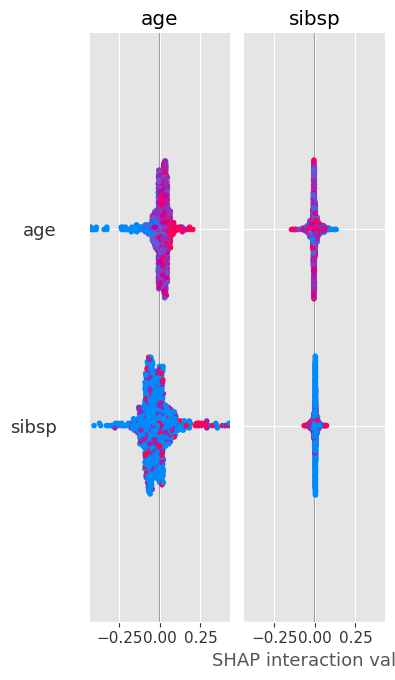

In [10]:
import shap

best_rf = grid_rf.best_estimator_
clf_model = best_rf.named_steps['clf']

cat_out = best_rf.named_steps['prep'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(cat_out)

X_train_transformed = best_rf.named_steps['prep'].transform(X_train)

importances = clf_model.feature_importances_
imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=imp_df, palette='viridis')
plt.title('Feature Importance')
plt.show()

explainer = shap.TreeExplainer(clf_model)
shap_values = explainer.shap_values(X_train_transformed)

if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

shap.summary_plot(shap_vals, X_train_transformed, feature_names=feature_names)